<b>Задание</b>
1. Познакомьтесь с данными.
2. Осуществите предобработку данных для дальнейшего исследования, обработайте аномалии.
3. Добавьте информацию из датасета region.csv.
4. Восстановите пропуски в столбце kitchen_area.
5. Исследуйте рынок недвижимости в РФ за представленный период. Величина исследования - цена за м2. Обработайте аномалии.
6. Когда выгодно покупать/продавать объект недвижимости?
7. Определите от каких признаков зависит стоимость объекта недвижимости. Найдите скрытые закономерности.
8. Выдвинете и проверьте собственную гипотезу статистическими методами.
9. Создайте модель прогноза цены объекта недвижимости.

**Прогресс выполнения**
1. сделано
2. сделано, но перепроверьте
3. добавил
4. восстановил
5. надо добавить выводы, мб что-то подредачить/исправить

In [1]:
# Описание датасета realty_18_21.csv
# Каждая строка - уникальное объявление, идентификатор объявление удален.
# date - дата объявления
# region - Регион
# building_type - Тип дома 0 - Другое. 1 - Панельный. 2 - Кирпично-монолитный. 3 - Кирпичный. 4 - Блочный 5 - Деревянный
# object_type -  1 - Вторичный рынок; 11 - Первичный рынок;
  # UPD: object_type -  1 - Вторичный рынок; 0 - Первичный рынок;
# level - Этаж
# levels - Число этажей
# rooms - Число комнат, где -1 означает студия
# area - Общая площадь
# kitchen_area - Площадь кухни
# price - Цена в руб.

# Загрузка библиотек и файлов

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st
from scipy.stats import t, norm
import xgboost as xgb
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

In [3]:
# Шаг 1: Установка git-lfs
!apt-get update
!apt-get install -y git-lfs

# Шаг 2: Инициализация Git LFS
!git lfs install

# Шаг 3: Клонирование репозитория
!git clone https://github.com/Inf1nity544/Realty.git

# Шаг 4: Переход в папку и загрузка LFS-файлов
%cd Realty
!git lfs pull

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Hit:3 http://archive.ubuntu.com/ubuntu noble InRelease
Get:4 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:5 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:6 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:8 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [78.0 kB]
Get:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:10 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:11 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.5 MB]
Get:12 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Packages [60.0 kB]
Get:13 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,55

In [4]:
df = pd.read_csv("realty_18_21.csv")

In [5]:
region = pd.read_csv("region.csv")

# Предобработка

In [6]:
sns.set_theme(style='darkgrid')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5477006 entries, 0 to 5477005
Data columns (total 10 columns):
 #   Column         Dtype  
---  ------         -----  
 0   price          int64  
 1   date           object 
 2   region         int64  
 3   building_type  int64  
 4   level          int64  
 5   levels         int64  
 6   rooms          int64  
 7   area           float64
 8   kitchen_area   float64
 9   object_type    int64  
dtypes: float64(2), int64(7), object(1)
memory usage: 417.9+ MB


In [8]:
# изменим тип данных у столбца date на datetime
df['date'] = pd.to_datetime(df['date'])

In [9]:
for i in df.columns:
  print(f'i: {df[i].unique()}')

i: [ 6050000  8650000  4000000 ... 12503160 11831910 13316200]
i: <DatetimeArray>
['2018-02-19 00:00:00', '2018-02-27 00:00:00', '2018-02-28 00:00:00',
 '2018-03-01 00:00:00', '2018-03-02 00:00:00', '2018-03-04 00:00:00',
 '2018-03-05 00:00:00', '2018-03-06 00:00:00', '2018-03-12 00:00:00',
 '2018-03-15 00:00:00',
 ...
 '2021-04-22 00:00:00', '2021-04-23 00:00:00', '2021-04-24 00:00:00',
 '2021-04-25 00:00:00', '2021-04-26 00:00:00', '2021-04-27 00:00:00',
 '2021-04-28 00:00:00', '2021-04-29 00:00:00', '2021-04-30 00:00:00',
 '2021-05-01 00:00:00']
Length: 1075, dtype: datetime64[ns]
i: [ 2661    81  2871  2843     3  3106  2922  2900  2722  6171  3230  4417
  5282  5368  3446  5520  6817  9579  2604  1010  9648  7793 13919  2860
  3019  4982  5241  3870  3991  2359  9654  2072  8090  4007 11171 10160
  7873  2594  8509 11416 11991  2880  5178 13913  6309  5952  6543  2328
  5993  2484 13098  4240  5789  1901 14880 10201  1491  2885  5794  2528
  4374  4695  5143  6937  2806 14368  573

In [10]:
# изменим тип даннх столбца object_type на boolean, т.к. он принмает два знаечения
# 1 - вторичный рынок, 0 - первичный рынок
df['object_type'] = df['object_type'].replace(11, 0)
df['object_type'] = df['object_type'].astype('boolean')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5477006 entries, 0 to 5477005
Data columns (total 10 columns):
 #   Column         Dtype         
---  ------         -----         
 0   price          int64         
 1   date           datetime64[ns]
 2   region         int64         
 3   building_type  int64         
 4   level          int64         
 5   levels         int64         
 6   rooms          int64         
 7   area           float64       
 8   kitchen_area   float64       
 9   object_type    boolean       
dtypes: boolean(1), datetime64[ns](1), float64(2), int64(6)
memory usage: 386.5 MB


In [11]:
# проверим данные по столбцам
df.head(-1)

,price,date,region,building_type,level,levels,rooms,area,kitchen_area,object_type
0,6050000,2018-02-19,2661,1,8,10,3,82.6,10.8,True
1,8650000,2018-02-27,81,3,5,24,2,69.1,12.0,True
2,4000000,2018-02-28,2871,1,5,9,3,66.0,10.0,True
3,1850000,2018-03-01,2843,4,12,16,2,38.0,5.0,False
4,5450000,2018-03-01,81,3,13,14,2,60.0,10.0,True
...,...,...,...,...,...,...,...,...,...,...
5477000,9000000,2021-05-01,2900,3,4,5,4,178.0,20.0,True
5477001,19739760,2021-05-01,3,1,8,17,4,93.2,13.8,False
5477002,12503160,2021-05-01,3,2,17,32,2,45.9,6.6,False
5477003,8800000,2021-05-01,2871,2,4,17,3,86.5,11.8,True


In [12]:
df['region'].unique()
df['building_type'].unique()
df['object_type'].unique()
df['rooms'].unique()

array([ 3,  2,  1,  4, -1,  5,  7,  6,  8,  9, -2, 10])

In [13]:
# изменил тип вывода значений для лучшей читаемости
with pd.option_context('display.float_format', '{:.0f}'.format):
    print(df.describe())

            price                           date  region  building_type  \
count     5477006                        5477006 5477006        5477006   
mean      4422029  2019-11-20 16:33:10.095173120    4307              2   
min   -2144967296            2018-02-19 00:00:00       3              0   
25%       1950000            2019-03-14 00:00:00    2661              1   
50%       2990000            2019-10-13 00:00:00    2922              2   
75%       4802000            2020-07-18 00:00:00    6171              3   
max    2147483647            2021-05-01 00:00:00   61888              5   
std      21507519                            NaN    3308              1   

        level  levels   rooms    area  kitchen_area  
count 5477006 5477006 5477006 5477006       5223295  
mean        6      11       2      54            11  
min         1       1      -2       0             0  
25%         2       5       1      38             7  
50%         5      10       2      48            10  


Мы видим отрицательную стоимость и аномально большую стоимость жилья. Этаж 39 выглядит немного подозрительно. Выбивыется значения -2  и 10 у кол-ва комнат. Аномально большие значения общей площади и явно ошибочные показатели площади кухни. Уберем из датасета очевидно неправильные значения. С аномально болшими значеними разберемся при обработке выбросов.

In [14]:
l = len(df)
# видим, что есть отрицательная стоимость, надо изменить df
df.query('price<0')
df = df.query('price>=0')
l - len(df)

365

In [15]:
l = len(df)
# уберем из данных строки, где этаж больше, чем кол-во этажей в здании
df.query('level > levels')
df = df.query('level <= levels')
(l - len(df))/len(df)

0.00019577874007249292

In [16]:
l = len(df)
# уберем уберем из данных строки, где кол-во комнат -2
df['rooms'].unique()
df.query('rooms==-2')
df = df.query('rooms!=-2')
l - len(df)

343

In [17]:
# зануляем строки китчен ареа, в которых площадь кухни больше общей площади
df.loc[(df['area'] <= df['kitchen_area']), 'kitchen_area'] = np.nan
df.loc[df['kitchen_area']==0, 'kitchen_area'] = np.nan

In [18]:
with pd.option_context('display.float_format', '{:.0f}'.format):
    print(df.describe())

           price                           date  region  building_type  \
count    5475226                        5475226 5475226        5475226   
mean     4536315  2019-11-20 17:48:26.532514816    4307              2   
min            0            2018-02-19 00:00:00       3              0   
25%      1950000            2019-03-14 00:00:00    2661              1   
50%      2990000            2019-10-13 00:00:00    2922              2   
75%      4803470            2020-07-18 00:00:00    6171              3   
max   2147483647            2021-05-01 00:00:00   61888              5   
std     15513250                            NaN    3308              1   

        level  levels   rooms    area  kitchen_area  
count 5475226 5475226 5475226 5475226       5217376  
mean        6      11       2      54            11  
min         1       1      -1       0             0  
25%         2       5       1      38             7  
50%         5      10       2      48            10  
75%      

Как мы видим, ошибочные значения были удалены, но по-прежнему остались аномальные. Также мы видим стоимость жилья 0, что странно.

In [19]:
# посмотрим на дубликаты и удалим их
# df.duplicated().sum()
# df[df.duplicated(keep=False)]
df = df.drop_duplicates()

In [20]:
# т.к. у Крыма два кода, посмотрим дубликаты исключительно для него
df.query('region in [7873, 6937]')[df.query('region in [7873, 6937]').duplicated(subset=['price', 'date', 'building_type', 'level', 'levels', 'rooms',
       'area', 'kitchen_area', 'object_type'], keep=False)]

,price,date,region,building_type,level,levels,rooms,area,kitchen_area,object_type


<Axes: ylabel='price'>

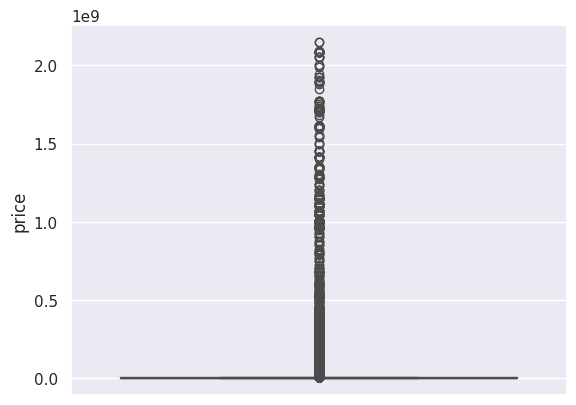

In [21]:
# посмотрим с помощью boxplot выбросы
sns.boxplot(df['price'])

<Axes: xlabel='price', ylabel='Density'>

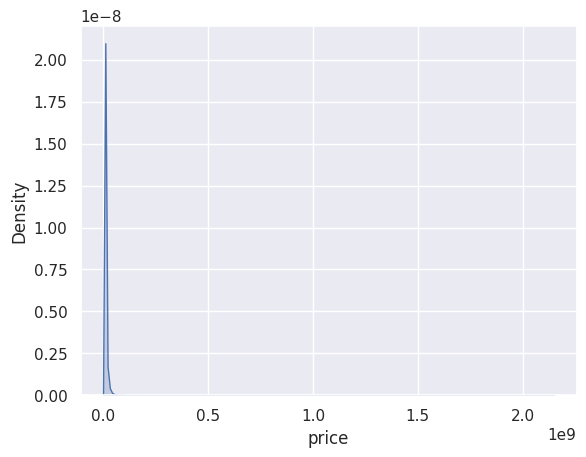

In [22]:
# посмотрим распределение
sns.kdeplot(df['price'], fill=True)

In [26]:
def remove_non_market_offers(df, price_col, region_col='region',
                            lower_q=0.05, upper_q=0.95):

    df_clean = df.copy()
    percentiles = df_clean.groupby('region')['price'].quantile([lower_q, upper_q]).unstack()
    percentiles.columns = ['lower_bound', 'upper_bound']

    df_clean = df_clean.join(percentiles, on='region')
    mask_to_remove = (
        (df_clean['price'] < df_clean['lower_bound']) |
        (df_clean['price'] > df_clean['upper_bound'])
    )
    total_rows = len(df_clean)
    rows_to_remove = mask_to_remove.sum()
    rows_to_keep = total_rows - rows_to_remove

    print(f"Всего строк: {total_rows:,}")
    print(f"Будет удалено: {rows_to_remove:,} ({rows_to_remove/total_rows*100:.2f}%)")
    print(f"Останется: {rows_to_keep:,} ({rows_to_keep/total_rows*100:.2f}%)")
    df_market = df_clean[~mask_to_remove].copy()
    df_market = df_market.drop(columns=['lower_bound', 'upper_bound'])
    df_removed = df_clean[mask_to_remove].drop(columns=['lower_bound', 'upper_bound'])
    df_removed['removal_reason'] = 'price_out_of_market_bounds'

    return df_market, df_removed

df_market_clean, df_removed = remove_non_market_offers(df, 'price', 'region', 0.05, 0.95)

Всего строк: 5,240,018
Будет удалено: 516,344 (9.85%)
Останется: 4,723,674 (90.15%)


Срезали данные по 5 и 95 процентилю, так как основной акцент в исследовании делаем на рыночные предложения

In [27]:
upper_bound = df_market_clean['area'].quantile(0.99)
upper_bound

np.float64(106.0)

In [28]:
#13,7 - самая маленькая квартира в РФ С 2018
mask_area_outliers = (
        (df_market_clean['area'] < 13.7) |
        (df_market_clean['area'] > upper_bound)
    )
dfc = df_market_clean[~mask_area_outliers]


Данные по площади срезали по 99 процентилю и информации о наименьшей квартире.

<Axes: ylabel='price'>

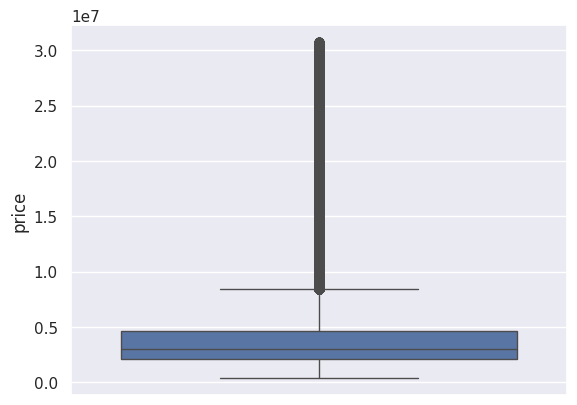

In [29]:
sns.boxplot(dfc['price'])

<Axes: xlabel='area', ylabel='Density'>

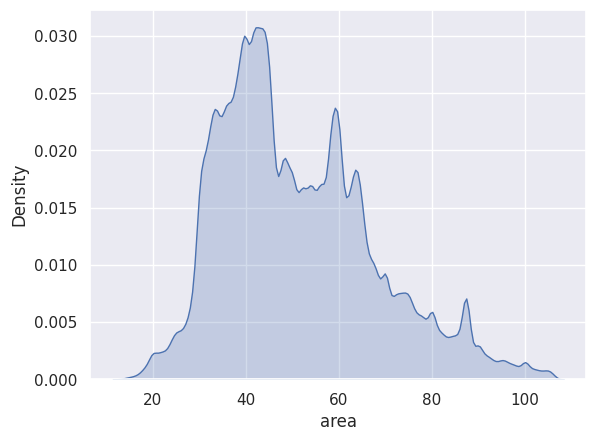

In [30]:
sns.kdeplot(dfc['area'], fill=True)

In [31]:
# посмотрим пропуски значений
for i in df.columns:
  print(f'{i}: {dfc[i].isnull().sum()}')

price: 0
date: 0
region: 0
building_type: 0
level: 0
levels: 0
rooms: 0
area: 0
kitchen_area: 226407
object_type: 0


In [32]:
# посмотрим на пропуски в столбце kitchen_area
dfc.query('kitchen_area.isnull()')

,price,date,region,building_type,level,levels,rooms,area,kitchen_area,object_type
19,1650000,2018-03-16,2843,3,5,5,2,51.00,NaN,True
42,4400000,2018-04-14,81,3,11,14,2,54.00,NaN,True
78,2980000,2018-06-04,4417,1,7,9,2,52.00,NaN,True
114,2900000,2018-07-12,81,3,2,9,1,37.50,NaN,True
136,5800000,2018-07-31,2661,2,6,14,1,47.10,NaN,True
...,...,...,...,...,...,...,...,...,...,...
5476919,3247500,2021-05-01,6543,0,7,12,-1,43.30,NaN,False
5476924,4250770,2021-05-01,6543,0,12,12,2,59.87,NaN,False
5476979,23319120,2021-05-01,3,2,2,11,3,96.36,NaN,False
5476982,13403880,2021-05-01,3,2,4,23,2,59.10,NaN,False


In [33]:
# проверим корреляцию между area и kitchen_area, чтобы заполнить пропуски
dfc1 = dfc[dfc['kitchen_area'].notnull()]
dfc1[['region','building_type','object_type','level','levels','rooms','area','kitchen_area','price']].corr()

,region,building_type,object_type,level,levels,rooms,area,kitchen_area,price
region,1.000000,-0.137328,-0.060653,-0.127527,-0.179769,-0.072462,-0.009476,-0.118977,-0.410970
building_type,-0.137328,1.000000,0.135753,-0.112346,-0.177532,0.022044,-0.020606,0.001162,-0.004008
object_type,-0.060653,0.135753,1.000000,-0.261098,-0.407196,0.131618,-0.051754,-0.255684,-0.101633
level,-0.127527,-0.112346,-0.261098,1.000000,0.658725,-0.096288,0.040654,0.205017,0.226833
levels,-0.179769,-0.177532,-0.407196,0.658725,1.000000,-0.153688,0.061037,0.309662,0.336221
rooms,-0.072462,0.022044,0.131618,-0.096288,-0.153688,1.000000,0.733610,0.155722,0.251002
area,-0.009476,-0.020606,-0.051754,0.040654,0.061037,0.733610,1.000000,0.422311,0.401234
kitchen_area,-0.118977,0.001162,-0.255684,0.205017,0.309662,0.155722,0.422311,1.000000,0.322028
price,-0.410970,-0.004008,-0.101633,0.226833,0.336221,0.251002,0.401234,0.322028,1.000000


In [34]:
#так как корреляция слабая, везде, то пробуем через xgboost

print(len(dfc1[dfc1['kitchen_area']==0]))
X, y = dfc1.drop(['kitchen_area','date','region'], axis=1), dfc1['kitchen_area']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=1)

model = xgb.XGBRegressor()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print(f'R^2 score: {r2_score(y_test, predictions):.3f}')
#получаем 0.5, что не оч, да и в будущем не будем его особо использовать, поэтому лучше оставим, используя, там где это требуется выборку без строк, где размер кухни = NaN

0
R^2 score: 0.506


In [35]:
region.query('code=="7873, 6937"')

,code,reg_name
36,"7873, 6937",Республика Крым


In [36]:
region = region.drop(36)
region = region.reset_index(drop=True)
region.loc[82] = [7873, 'Республика Крым']
region.loc[83] = [6937, 'Республика Крым']

In [37]:
# изменим тип данных
region['code'] = region['code'].astype('int64')
region.info()

<class 'pandas.core.frame.DataFrame'>
Index: 84 entries, 0 to 83
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   code      84 non-null     int64 
 1   reg_name  84 non-null     object
dtypes: int64(1), object(1)
memory usage: 2.0+ KB


In [38]:
# проверим полноту данных
len(region['code'].unique())-len(dfc['region'].unique())

0

In [39]:
# добавим данные из файла region
dfc = pd.merge(
    dfc1,
    region,
    left_on='region',
    right_on='code',
    how='left').drop('code', axis=1)
dfc

,price,date,region,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name
0,6050000,2018-02-19,2661,1,8,10,3,82.6,10.8,True,Санкт-Петербург
1,8650000,2018-02-27,81,3,5,24,2,69.1,12.0,True,Московская область
2,4000000,2018-02-28,2871,1,5,9,3,66.0,10.0,True,Нижегородская область
3,1850000,2018-03-01,2843,4,12,16,2,38.0,5.0,False,Краснодарский край
4,5450000,2018-03-01,81,3,13,14,2,60.0,10.0,True,Московская область
...,...,...,...,...,...,...,...,...,...,...,...
4443723,12850000,2021-05-01,3,2,12,24,1,41.0,9.0,True,Москва
4443724,19739760,2021-05-01,3,1,8,17,4,93.2,13.8,False,Москва
4443725,12503160,2021-05-01,3,2,17,32,2,45.9,6.6,False,Москва
4443726,11831910,2021-05-01,3,1,8,33,2,52.1,18.9,False,Москва


In [40]:
# объединение произошло успешно, в полной мере
dfc['reg_name'].isnull().sum()

np.int64(0)

# Исследовательский анализ данных

## Исследование рынка недвижимости

Исследуйте рынок недвижимости в РФ за представленный период. Величина исследования - цена за м2. Обработайте аномалии.

In [41]:
# добавим столбец с исследуемой величиной
dfc['price_m'] = (dfc['price']/dfc['area']).round(2)
# уберём данные за февраль 2018 года, т.к. данные неполные
dfc = dfc.query('date>"2018-02-28"')

In [42]:
# добавим столбец с месяцем и годом
dfc['ym'] = dfc['date'].dt.strftime('%Y-%m')
dfc['year']= dfc['date'].dt.strftime('%Y')
dfc['year'].head()

/tmp/ipykernel_3633/2527044474.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfc['ym'] = dfc['date'].dt.strftime('%Y-%m')
/tmp/ipykernel_3633/2527044474.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfc['year']= dfc['date'].dt.strftime('%Y')


,year
3,2018
4,2018
5,2018
6,2018
7,2018


In [43]:
df_data= dfc.pivot_table(index='object_type',aggfunc='sum',values='area')
df_data

,area
object_type,
False,6.645882e+07
True,1.604705e+08


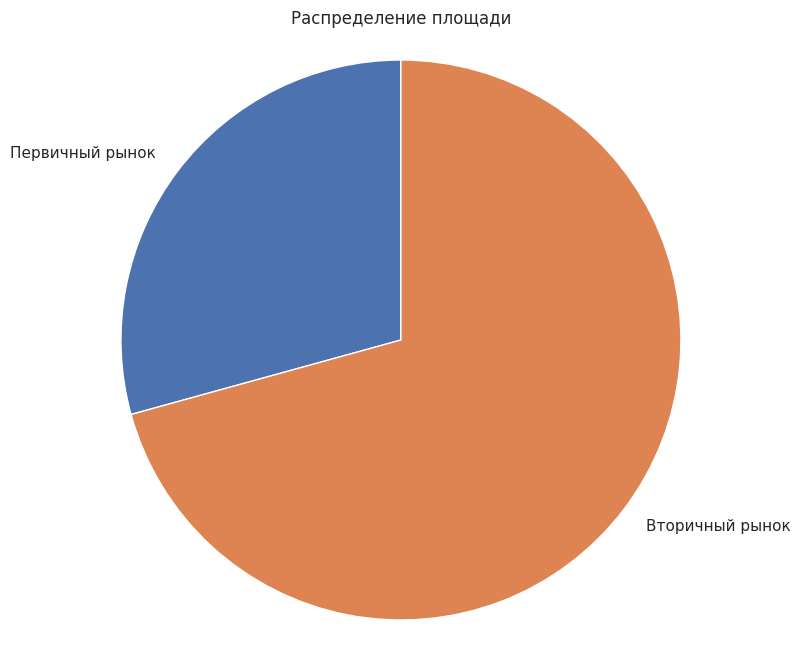

In [44]:
plt.figure(figsize=(10, 8))
plt.pie(
    df_data['area'],
    labels=['Первичный рынок', "Вторичный рынок"],
    startangle=90
)
plt.title('Распределение площади')
plt.axis('equal')
plt.show()

На вторичный рынок во всей России приходиться, более 70% площади, что не удивительно я является совершенно нормальным, для всех стран

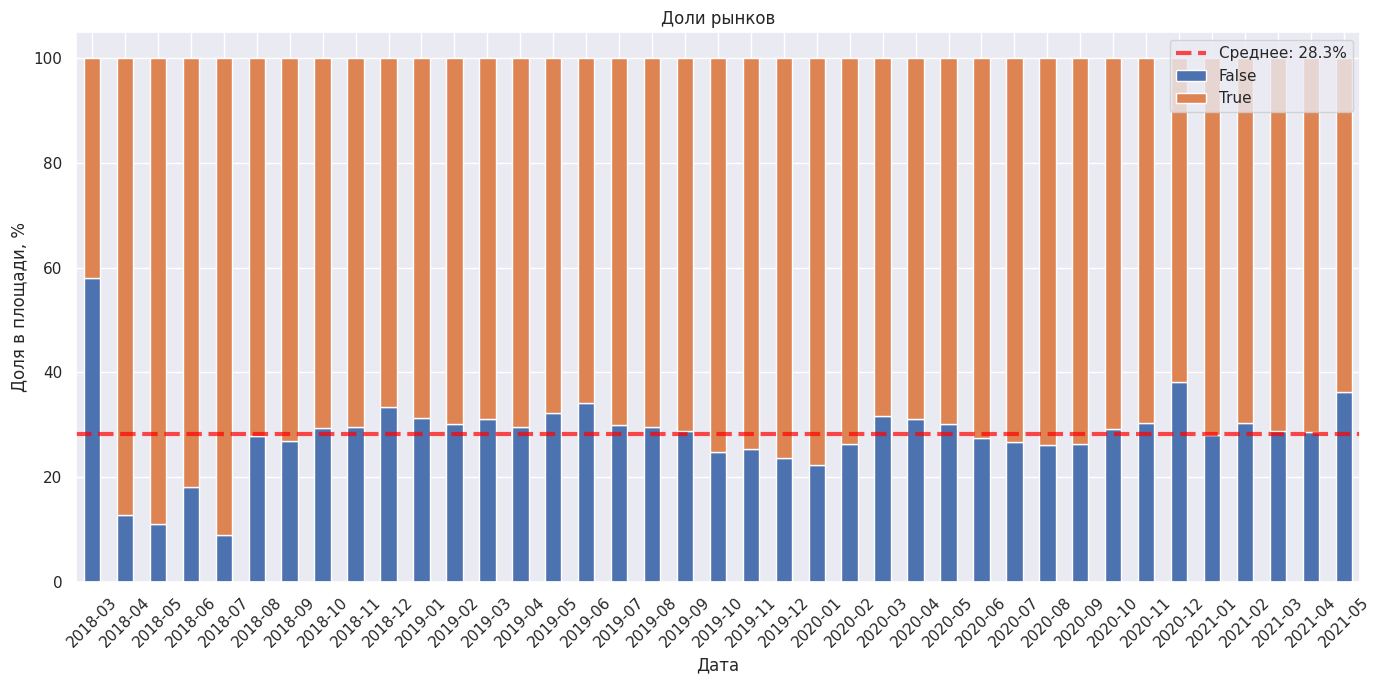

In [45]:
df_sum = dfc.pivot_table(
    index='ym',
    columns='object_type',
    values='area',
    aggfunc='sum',
    fill_value=0
)
df_sum
total_per_month = df_sum.sum(axis=1)
df_percentage = df_sum.div(total_per_month,axis=0) * 100
ax = df_percentage.plot(kind='bar', stacked=True, figsize=(14, 7))

# Только среднее для вторичного рынка красным пунктиром
secondary_mean = df_percentage[False].mean()
ax.axhline(y=secondary_mean, color='red', linestyle='--',
           linewidth=3, alpha=0.7,
           label=f'Среднее: {secondary_mean:.1f}%')

plt.title('Доли рынков')
plt.legend()
plt.xlabel('Дата')
plt.ylabel('Доля в площади, %')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

На данном графике заметны сильные коллебания, хотя нами и были удаленны данные за февраль 2018 года, всё равно значения в начале датасета изменяются от 55 до 8%, однако начина с августа доля первичного рынка приходит к среднему показателю и начинает двигаться возле него с постепенными колебаниями.

Можно отметить и следующее: на гарнице 2019 и 2020 года доля первички проседает, возможно рынок ожидает того, что новые льготные предложеия о ипотеке на новостройки наберут обороты.

In [46]:
#фильтруем регионы у которых менее 1000 записей, так как иначе данные будут искажены.
region_counts = dfc.groupby('reg_name').size()
valid_regions = region_counts[region_counts > 1000].index
dfc_filtered = dfc[dfc['reg_name'].isin(valid_regions)]

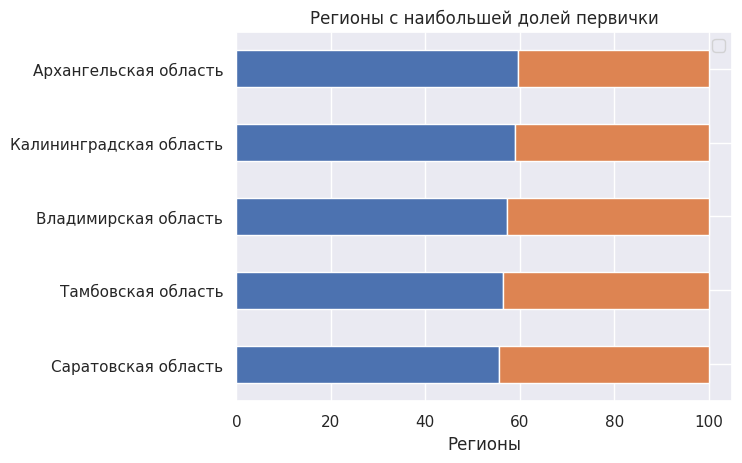

In [47]:
df_sum = dfc_filtered.pivot_table(
    index='reg_name',
    columns='object_type',
    values='area',
    aggfunc='sum',
    fill_value=0
)
df_sum
total_per_month = df_sum.sum(axis=1)
df_percentage = df_sum.div(total_per_month,axis=0) * 100
leaders = df_percentage.sort_values(False, ascending=False).head(5)
leaders = leaders.sort_values(False, ascending=True)
leaders.plot(kind='barh',stacked=True)
plt.title('Регионы с наибольшей долей первички')
plt.legend('')
plt.xlabel('Регионы')
plt.ylabel('')
plt.show()

Наибольшая доля первичного рынка представлена в активно развивающихся городах центральной россии и СЗФО, калининград к примеру, сильно увеличил сою туристическую привлекательность за последние годы, возможно вместе с туристами в регион начали приходить и новые застройщики.

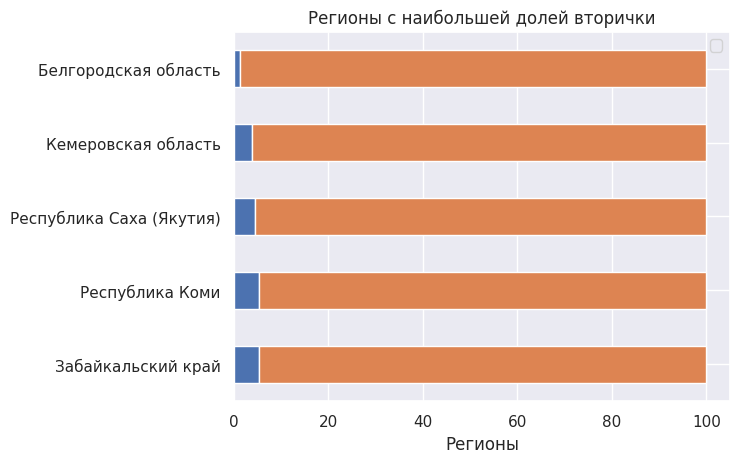

In [48]:
df_sum = dfc_filtered.pivot_table(
    index='reg_name',
    columns='object_type',
    values='area',
    aggfunc='sum',
    fill_value=0
)
df_sum
total_per_month = df_sum.sum(axis=1)
df_percentage = df_sum.div(total_per_month,axis=0) * 100
leaders = df_percentage.sort_values(True, ascending=False).head(5)
leaders = leaders.sort_values(True, ascending=True)
leaders.plot(kind='barh',stacked=True)
plt.title('Регионы с наибольшей долей вторички')
plt.legend('')
plt.xlabel('Регионы')
plt.ylabel('')
plt.show()

Аутсайдерами же являеются регионы с тяжелыми политическими или погодными условиями, а так же низким ВРП и иными МСЦ показателями.

object_type     False       True 
ym                               
2018-09      6.993007   93.006993
2018-10      9.459459   90.540541
2018-11      7.502680   92.497320
2018-12      6.793802   93.206198
2019-01      6.555091   93.444909
2019-02      7.034632   92.965368
2019-03      6.662040   93.337960
2019-04      6.297710   93.702290
2019-05      5.822137   94.177863
2019-06      5.475990   94.524010
2019-07      6.560135   93.439865
2019-08      2.331002   97.668998
2019-09      4.269663   95.730337
2019-10      4.250000   95.750000
2019-11      4.067797   95.932203
2019-12      3.076923   96.923077
2020-01      5.633803   94.366197
2020-02      4.470588   95.529412
2020-03      4.326329   95.673671
2020-04      2.821317   97.178683
2020-05      1.470588   98.529412
2020-06      3.600823   96.399177
2020-07      4.386839   95.613161
2020-08      3.343465   96.656535
2020-09      2.055623   97.944377
2020-10      1.737757   98.262243
2020-11      2.357564   97.642436
2020-12      5

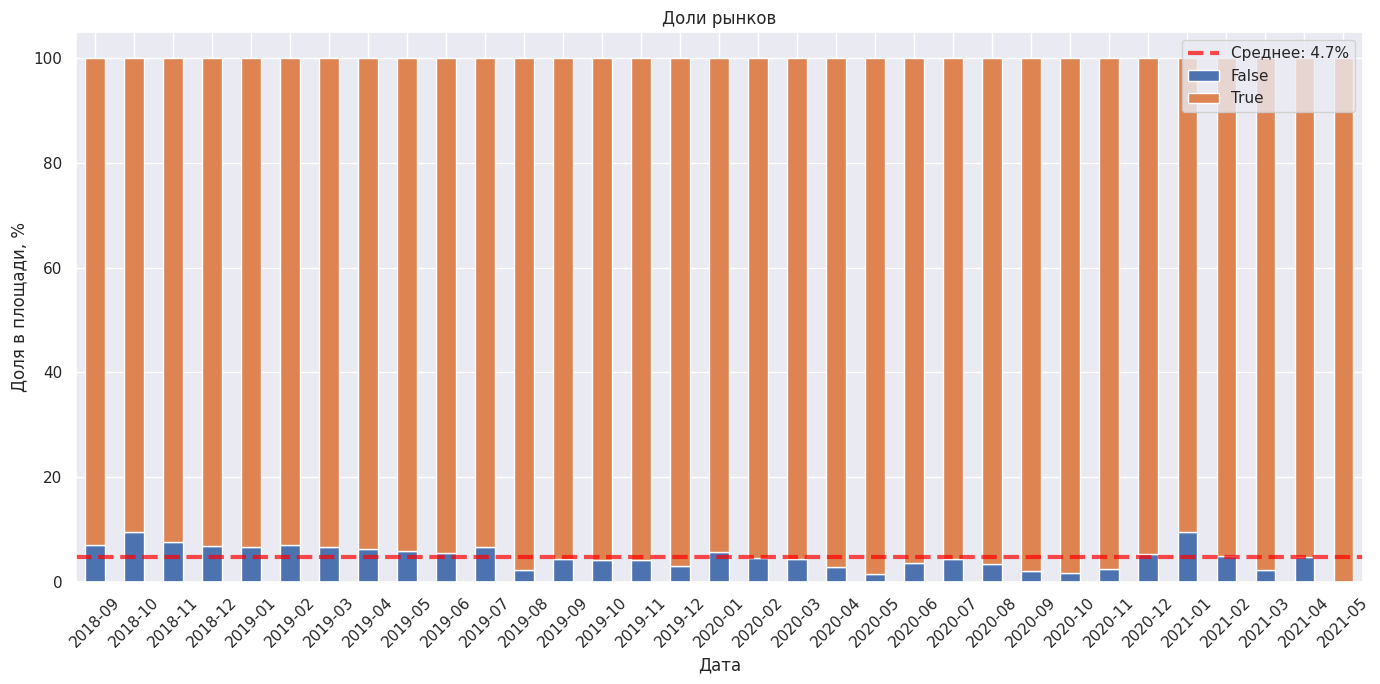

In [49]:
df_sum = dfc[dfc['reg_name']=='Забайкальский край'].pivot_table(
    index='ym',
    columns='object_type',
    values='area',
    aggfunc='count',
    fill_value=0
)
df_sum
total_per_month = df_sum.sum(axis=1)
df_percentage = df_sum.div(total_per_month,axis=0) * 100
print(df_percentage)
ax = df_percentage.plot(kind='bar', stacked=True, figsize=(14, 7))

# Только среднее для вторичного рынка красным пунктиром
secondary_mean = df_percentage[False].mean()
ax.axhline(y=secondary_mean, color='red', linestyle='--',
           linewidth=3, alpha=0.7,
           label=f'Среднее: {secondary_mean:.1f}%')

plt.title('Доли рынков')
plt.legend()
plt.xlabel('Дата')
plt.ylabel('Доля в площади, %')
plt.xticks(rotation=45)
plt.tight_layout()

(Пытался проверить идею о том, что Дальневосточная ипотека повлияла на рынок первички, но для Забайкальского края гипотеза не оправдалась, нужно проверять на приморском крае, так как он сейчас является центром притяжения застрощиков из-за высокой рыночной процентной ставки.Но у приморья мало данных)

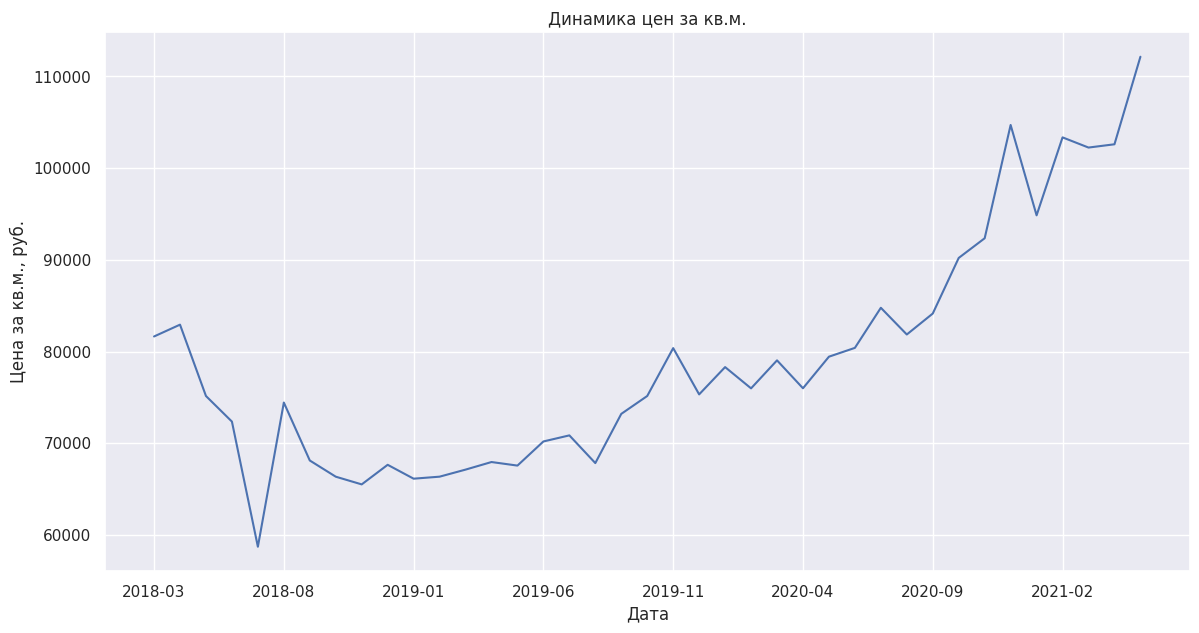

In [50]:
price = dfc.groupby(['ym'])['price_m'].mean()
price.plot(
    figsize=(14,7),
    xlabel='Дата',
    ylabel='Цена за кв.м., руб.',
    title='Динамика цен за кв.м.')
plt.show()

На графике можно отметить, что цены стабильно ниже в августе, это повторялось в 18 и 19-ом году, частично подверждается 20-ым, однако временной промежуток слишком мал что бы говорить о какой-либо тенденции.

In [51]:
region_counts = dfc[dfc['year']=='2019'].groupby('reg_name').size()
region_counts1 = dfc[dfc['year']=='2021'].groupby('reg_name').size()
valid_regions = region_counts[region_counts > 1000].index
valid_regions1 = region_counts1[region_counts1 > 1000].index
common_valid = set(valid_regions) & set(valid_regions1)
dfc_filtered1 = dfc[dfc['reg_name'].isin(common_valid)]
dfc_filtered1 = dfc_filtered1[(dfc_filtered1['year']=='2019') | (dfc_filtered1['year']=='2021')]

In [52]:
dfc_filtered1

,price,date,region,building_type,level,levels,rooms,area,kitchen_area,object_type,reg_name,price_m,ym,year
692920,3100000,2019-01-01,2843,2,2,8,1,35.0,9.0,True,Краснодарский край,88571.43,2019-01,2019
692921,2300000,2019-01-01,2843,2,12,13,1,34.1,8.6,True,Краснодарский край,67448.68,2019-01,2019
692922,3900000,2019-01-01,2843,3,4,5,1,53.0,15.0,True,Краснодарский край,73584.91,2019-01,2019
692923,3450000,2019-01-01,2843,2,4,13,2,57.0,15.0,True,Краснодарский край,60526.32,2019-01,2019
692924,4380000,2019-01-01,2843,0,5,6,2,74.0,11.0,True,Краснодарский край,59189.19,2019-01,2019
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4443723,12850000,2021-05-01,3,2,12,24,1,41.0,9.0,True,Москва,313414.63,2021-05,2021
4443724,19739760,2021-05-01,3,1,8,17,4,93.2,13.8,False,Москва,211800.00,2021-05,2021
4443725,12503160,2021-05-01,3,2,17,32,2,45.9,6.6,False,Москва,272400.00,2021-05,2021
4443726,11831910,2021-05-01,3,1,8,33,2,52.1,18.9,False,Москва,227100.00,2021-05,2021


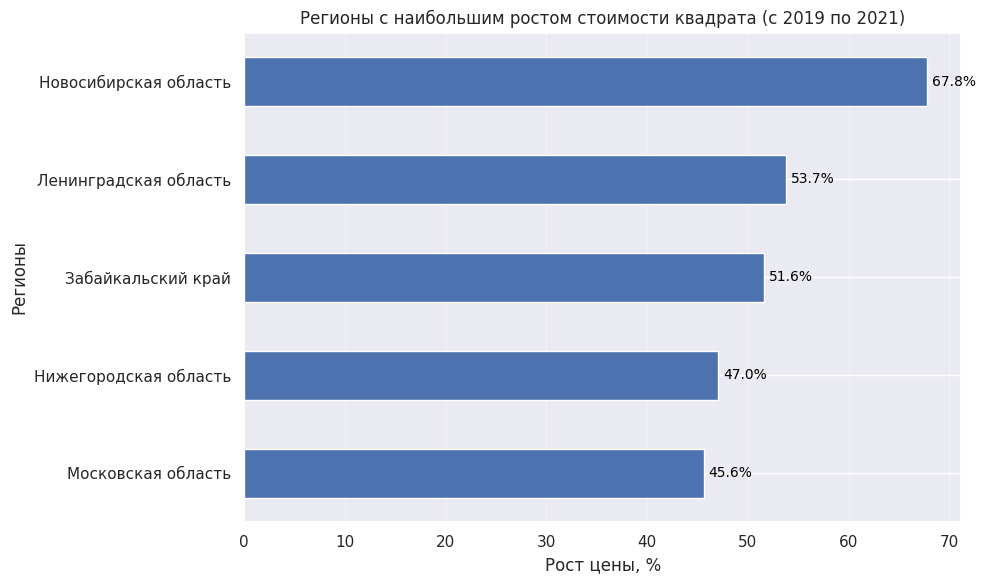

In [53]:
df_izm = dfc_filtered1.pivot_table(
    index='reg_name',
    columns='year',
    values='price_m',
    aggfunc='mean',
    fill_value=0
)
df_izm
df_izm['pct_change'] = ((df_izm['2021'] - df_izm['2019']) /
                               df_izm['2019'] * 100)

leaders = df_izm.sort_values('pct_change', ascending=False).head(5)
leaders = leaders.sort_values('pct_change', ascending=True)
ax = leaders['pct_change'].plot(kind='barh', figsize=(10, 6))

for i, (idx, value) in enumerate(leaders['pct_change'].items()):
    ax.text(value + 0.5, i, f'{value:.1f}%',
            va='center', ha='left', fontsize=10, color='black')

plt.title('Регионы с наибольшим ростом стоимости квадрата (c 2019 по 2021)')
plt.xlabel('Рост цены, %')
plt.ylabel('Регионы')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

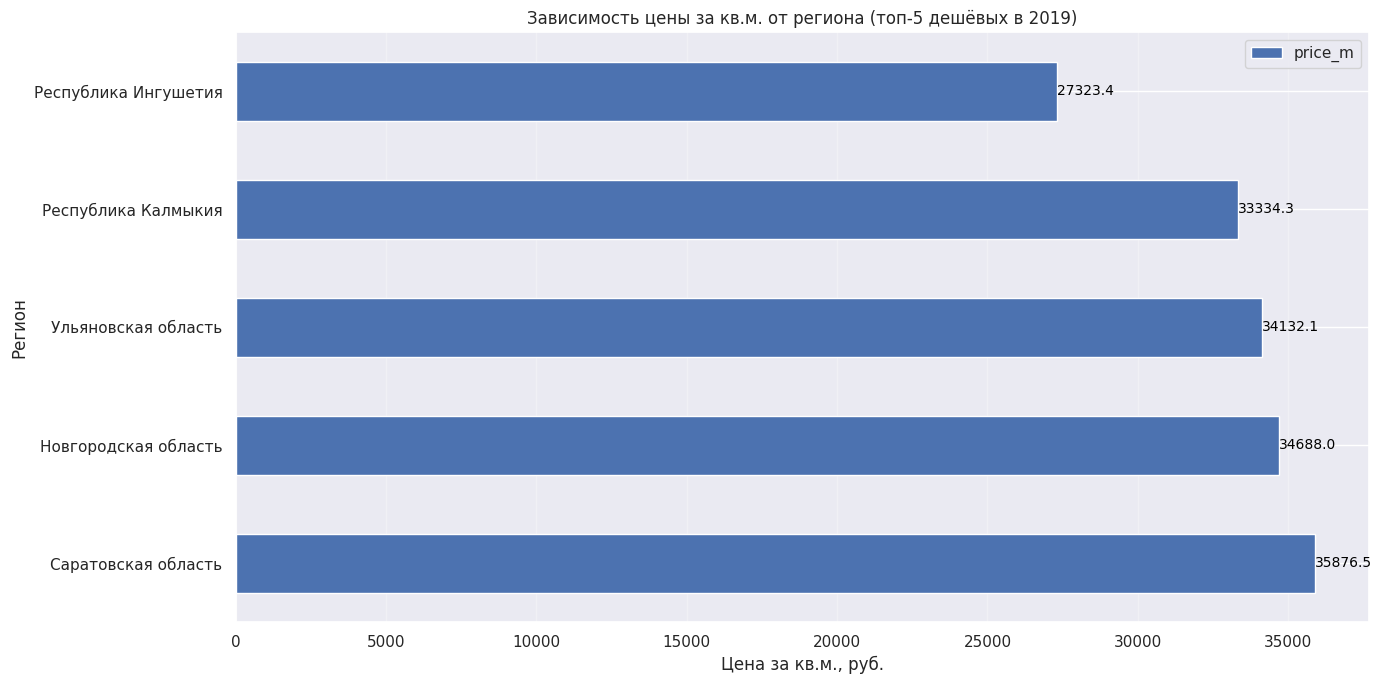

In [54]:
# Завсимость цен на жильё от региона
price_region_desc = dfc[dfc['year']=='2019'].pivot_table(
    index='reg_name',
    values='price_m',
    aggfunc='mean',
    fill_value=0
)

price_region_desc = price_region_desc.sort_values('price_m',ascending=True).head(5)
price_region_desc = price_region_desc.sort_values('price_m',ascending=False)

ax = price_region_desc.plot(kind='barh',
    figsize=(14,7))

for i, (idx, value) in enumerate(price_region_desc['price_m'].items()):
    ax.text(value + 0.5, i, f'{value:.1f}',
            va='center', ha='left', fontsize=10, color='black')

plt.title('Зависимость цены за кв.м. от региона (топ-5 дешёвых в 2019)')
plt.xlabel('Цена за кв.м., руб.')
plt.ylabel('Регион')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

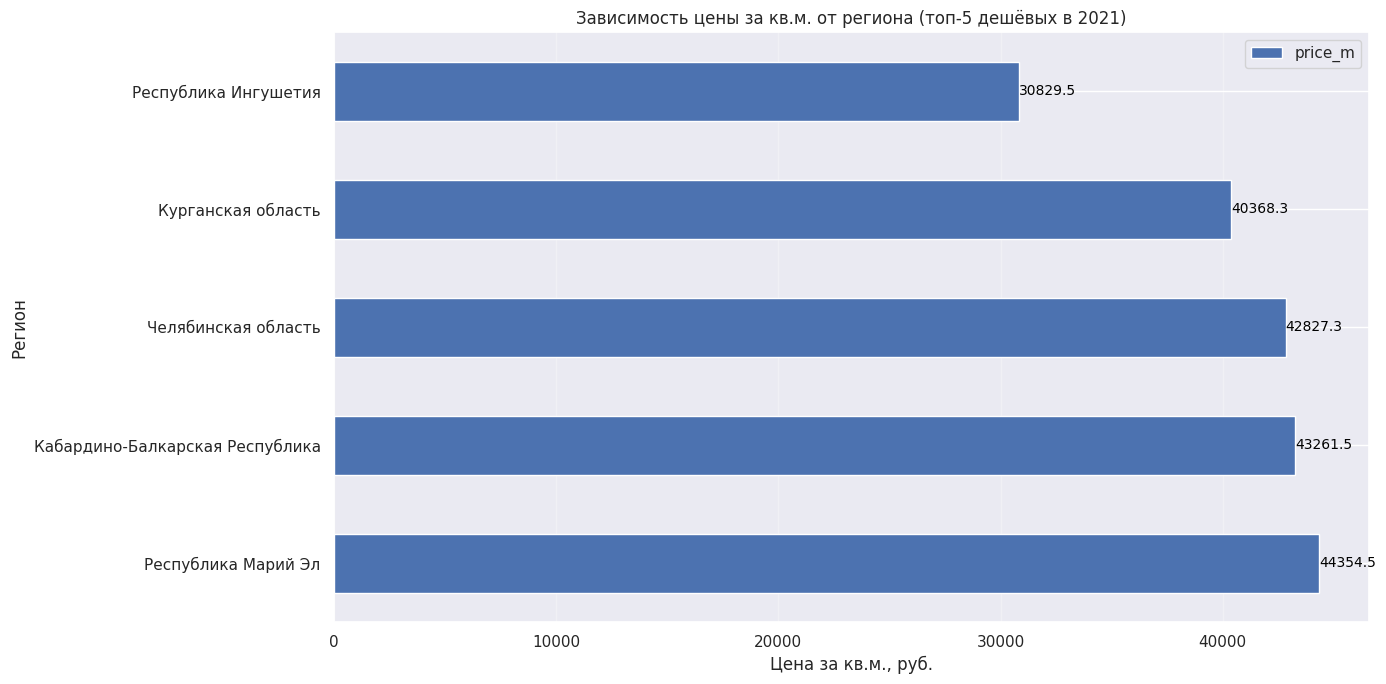

In [55]:
# Завсимость цен на жильё от региона
price_region_desc = dfc[dfc['year']=='2021'].pivot_table(
    index='reg_name',
    values='price_m',
    aggfunc='mean',
    fill_value=0
)

price_region_desc = price_region_desc.sort_values('price_m',ascending=True).head(5)
price_region_desc = price_region_desc.sort_values('price_m',ascending=False)

ax = price_region_desc.plot(kind='barh',
    figsize=(14,7))

for i, (idx, value) in enumerate(price_region_desc['price_m'].items()):
    ax.text(value + 0.5, i, f'{value:.1f}',
            va='center', ha='left', fontsize=10, color='black')

plt.title('Зависимость цены за кв.м. от региона (топ-5 дешёвых в 2021)')
plt.xlabel('Цена за кв.м., руб.')
plt.ylabel('Регион')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

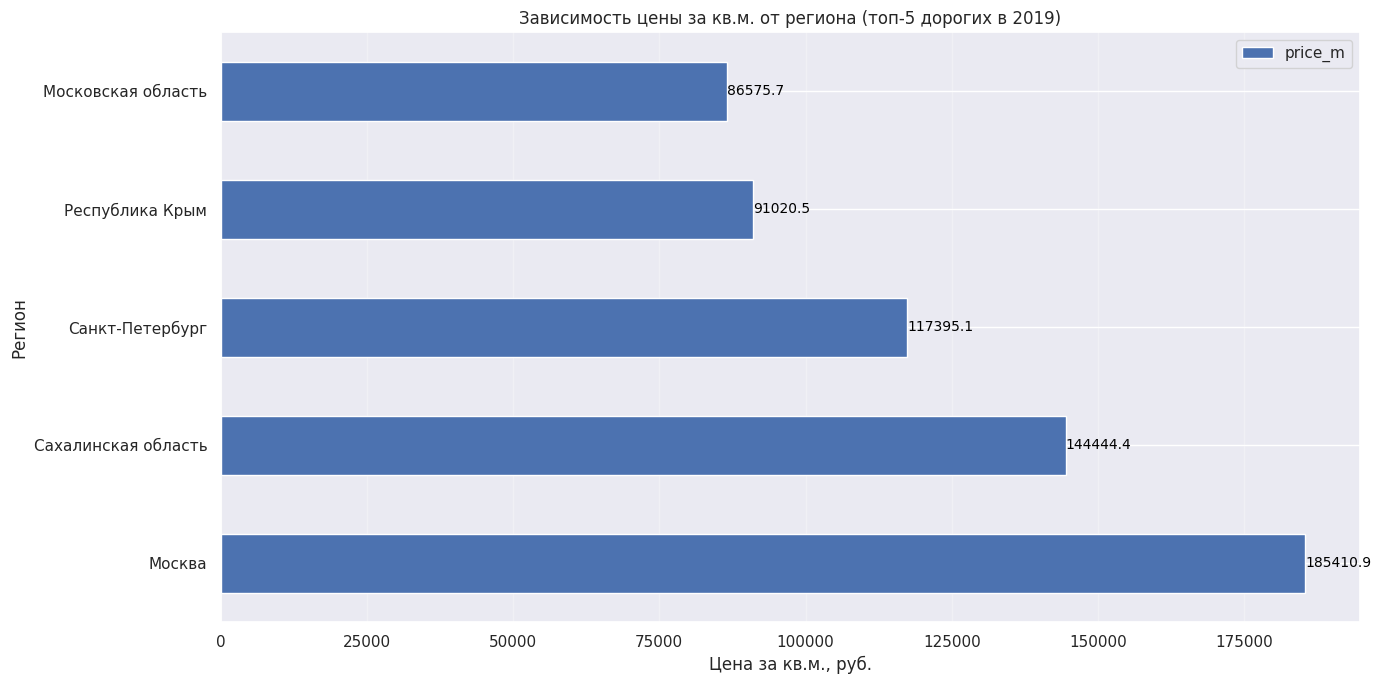

In [56]:
# Завсимость цен на жильё от региона
price_region_desc = dfc[dfc['year']=='2019'].pivot_table(
    index='reg_name',
    values='price_m',
    aggfunc='mean',
    fill_value=0
)

price_region_desc = price_region_desc.sort_values('price_m',ascending=False).head(5)

ax = price_region_desc.plot(kind='barh',
    figsize=(14,7))

for i, (idx, value) in enumerate(price_region_desc['price_m'].items()):
    ax.text(value + 0.5, i, f'{value:.1f}',
            va='center', ha='left', fontsize=10, color='black')

plt.title('Зависимость цены за кв.м. от региона (топ-5 дорогих в 2019)')
plt.xlabel('Цена за кв.м., руб.')
plt.ylabel('Регион')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

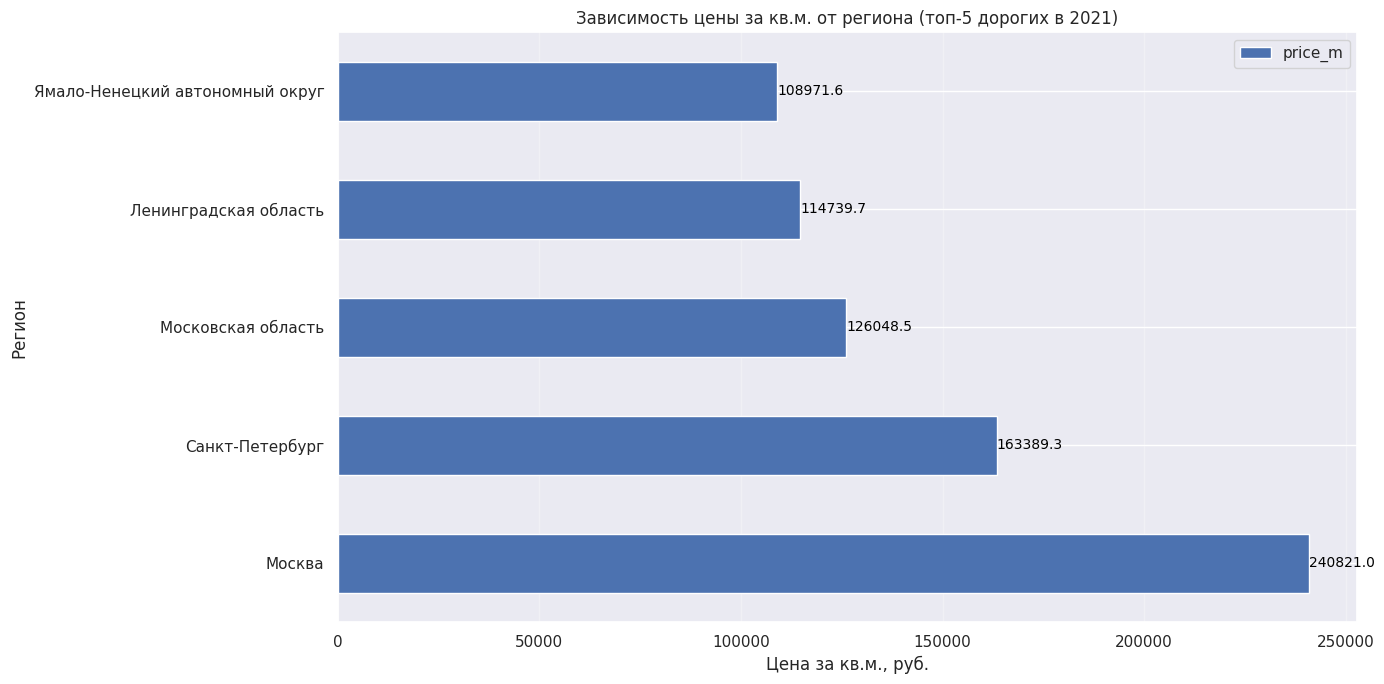

In [57]:
# Завсимость цен на жильё от региона
price_region_desc = dfc[dfc['year']=='2021'].pivot_table(
    index='reg_name',
    values='price_m',
    aggfunc='mean',
    fill_value=0
)

price_region_desc = price_region_desc.sort_values('price_m',ascending=False).head(5)

ax = price_region_desc.plot(kind='barh',
    figsize=(14,7))

for i, (idx, value) in enumerate(price_region_desc['price_m'].items()):
    ax.text(value + 0.5, i, f'{value:.1f}',
            va='center', ha='left', fontsize=10, color='black')

plt.title('Зависимость цены за кв.м. от региона (топ-5 дорогих в 2021)')
plt.xlabel('Цена за кв.м., руб.')
plt.ylabel('Регион')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

На графиках видно большую дифференциацию по величине средней стоимости квадратного метра

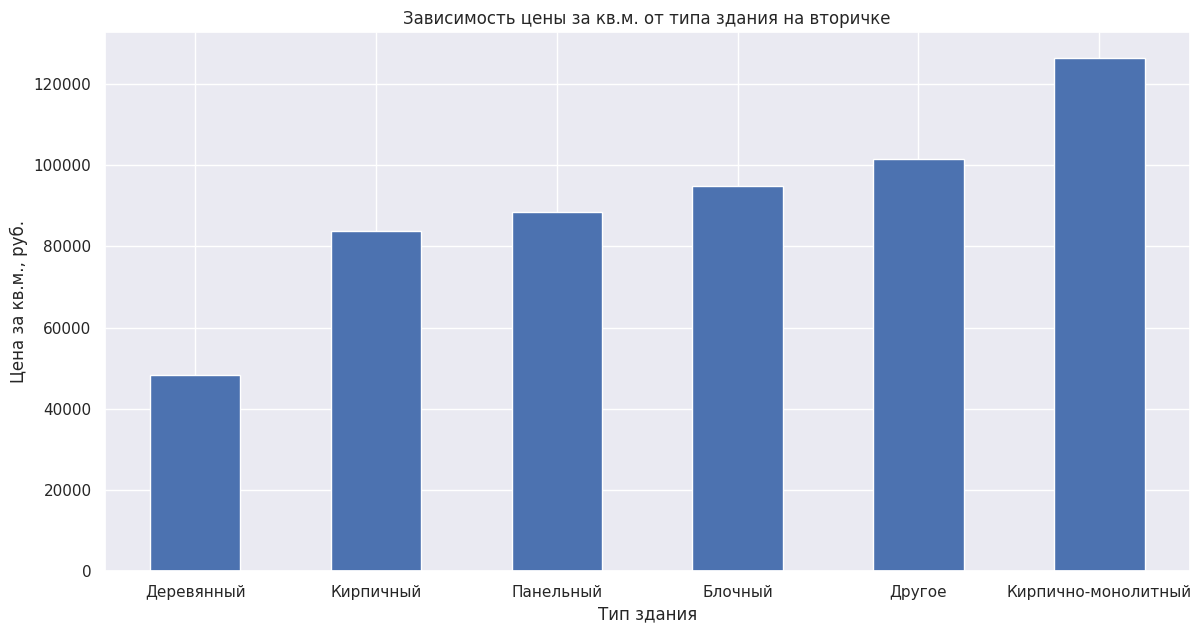

In [58]:
# Завсимость цен на жильё от типа здания
price_bt = dfc[(dfc['year']=='2021')&(dfc['object_type']==1)].groupby(['building_type'])['price_m'].mean().sort_values().reset_index()
# заменим цифры на понятные обозначения
d = {
    0: "Другое",
    1: "Панельный",
    2: "Кирпично-монолитный",
    3: "Кирпичный",
    4: "Блочный",
    5: "Деревянный"
}
price_bt['building_type'] = price_bt['building_type'].map(d)
price_bt.plot(kind='bar',
    figsize=(14,7),
    x='building_type',
    xlabel='Тип здания',
    ylabel='Цена за кв.м., руб.',
    title='Зависимость цены за кв.м. от типа здания на вторичке',
    rot=0,
    legend=False)
plt.show()

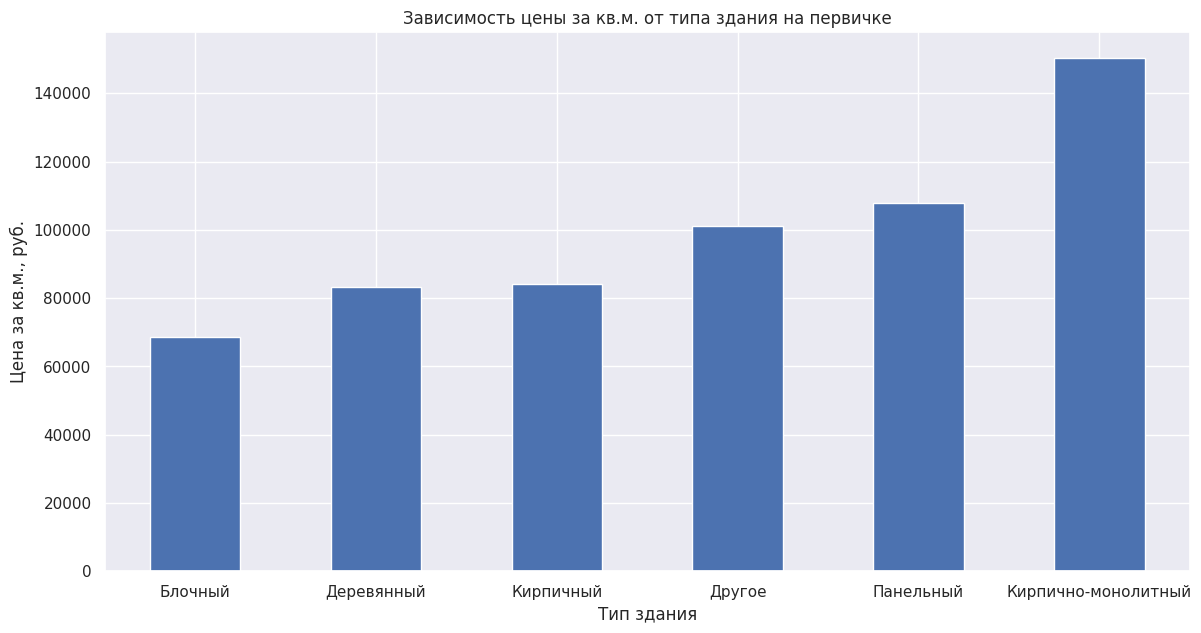

In [59]:
# Завсимость цен на жильё от типа здания
price_bt = dfc[(dfc['year']=='2021')&(dfc['object_type']==0)].groupby(['building_type'])['price_m'].mean().sort_values().reset_index()
# заменим цифры на понятные обозначения
d = {
    0: "Другое",
    1: "Панельный",
    2: "Кирпично-монолитный",
    3: "Кирпичный",
    4: "Блочный",
    5: "Деревянный"
}
price_bt['building_type'] = price_bt['building_type'].map(d)
price_bt.plot(kind='bar',
    figsize=(14,7),
    x='building_type',
    xlabel='Тип здания',
    ylabel='Цена за кв.м., руб.',
    title='Зависимость цены за кв.м. от типа здания на первичке',
    rot=0,
    legend=False)
plt.show()

На обоих графиках так же видна дифференциация по типу материалов, из которых потроен дом. Кирпично-монолитный существенно дороже остальных, так как представлен в основном в бизнесс классе

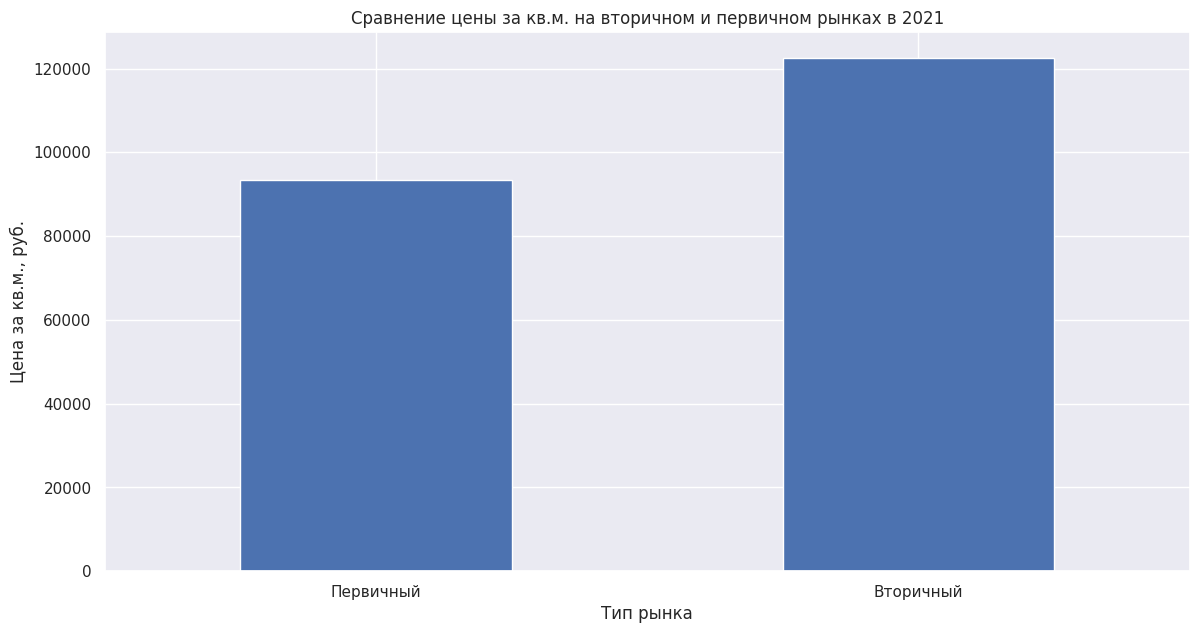

In [60]:
# Сравним стоимость кв м на первичном и вторичном рынках
price_ot = dfc[dfc['year']=='2021'].groupby(['object_type'])['price_m'].mean().sort_values().reset_index()
# заменим цифры на понятные обозначения
d = {
    True: "Первичный",
    False: "Вторичный",
}
price_ot['object_type'] = price_ot['object_type'].map(d)
price_ot.plot(kind='bar',
    figsize=(14,7),
    x='object_type',
    xlabel='Тип рынка',
    ylabel='Цена за кв.м., руб.',
    title='Сравнение цены за кв.м. на вторичном и первичном рынках в 2021',
    rot=0,
    legend=False)
plt.show()

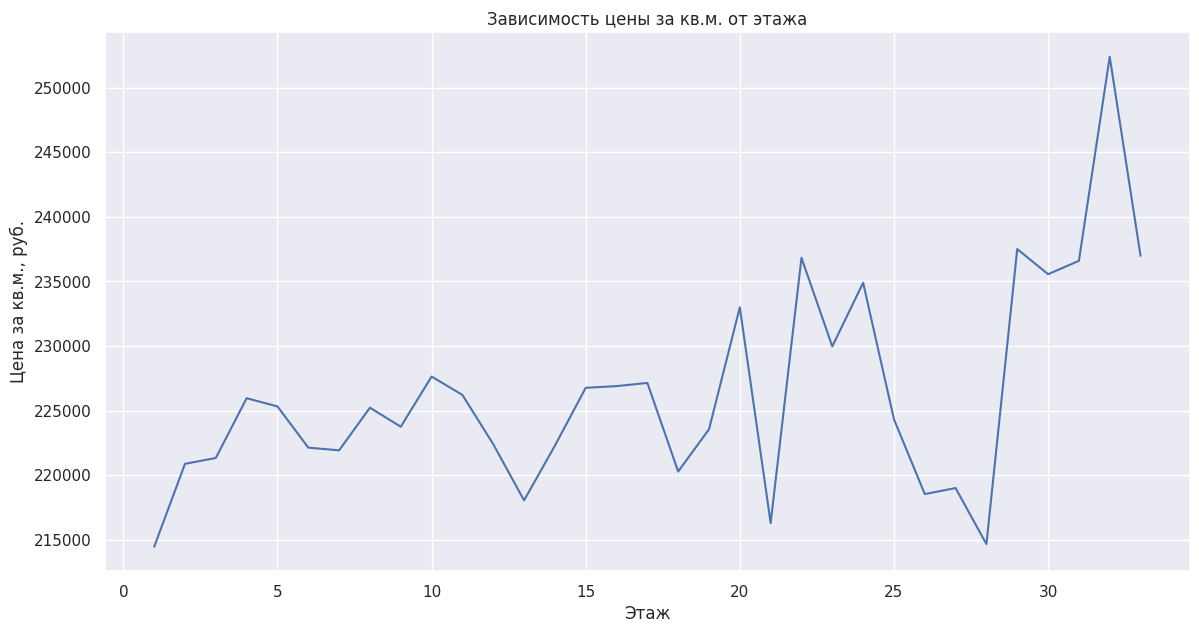

In [61]:
dfc
price =  dfc[(dfc['year']=='2021')&(dfc['reg_name']=='Москва')&(dfc['building_type']==1)].groupby(['level'])['price_m'].mean()
price.plot(
    figsize=(14,7),
    xlabel='Этаж',
    ylabel='Цена за кв.м., руб.',
    title='Зависимость цены за кв.м. от этажа')
plt.show()

## Когда выгодно покупать/продавать объект недвижимости

In [62]:
df

,price,date,region,building_type,level,levels,rooms,area,kitchen_area,object_type
0,6050000,2018-02-19,2661,1,8,10,3,82.6,10.8,True
1,8650000,2018-02-27,81,3,5,24,2,69.1,12.0,True
2,4000000,2018-02-28,2871,1,5,9,3,66.0,10.0,True
3,1850000,2018-03-01,2843,4,12,16,2,38.0,5.0,False
4,5450000,2018-03-01,81,3,13,14,2,60.0,10.0,True
...,...,...,...,...,...,...,...,...,...,...
5477001,19739760,2021-05-01,3,1,8,17,4,93.2,13.8,False
5477002,12503160,2021-05-01,3,2,17,32,2,45.9,6.6,False
5477003,8800000,2021-05-01,2871,2,4,17,3,86.5,11.8,True
5477004,11831910,2021-05-01,3,1,8,33,2,52.1,18.9,False


In [63]:
#добавим столбец с месяцем и сезоном
dfc['month'] = dfc['date'].dt.month
dfc['season'] = dfc['month'].map({1: "зима",
                                2: "зима",
                                3: "весна",
                                4: "весна",
                                5: "весна",
                                6: "лето",
                                7: "лето",
                                8: "лето",
                                9: "осень",
                                10: "осень",
                                11: "осень",
                                12: "зима"})

/tmp/ipykernel_3633/201592016.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfc['month'] = dfc['date'].dt.month
/tmp/ipykernel_3633/201592016.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfc['season'] = dfc['month'].map({1: "зима",


In [64]:
dfc2020 = dfc[dfc['year']=='2020']


In [65]:
#посмотрим среднюю стоимость квадратного метра по сезонам
price_ses = dfc.pivot_table(index = 'season', aggfunc={'price':'sum', 'area':'sum'})
price_ses['price_per_m'] = (price_ses['price'] / price_ses['area']).round(2)
price_ses

,area,price,price_per_m
season,,,
весна,60313361.34,4774002732882,79153.32
зима,56675426.75,4343461338355,76637.47
лето,43563488.64,3283082535917,75363.17
осень,66377023.98,5034472277014,75846.61


<Axes: xlabel='season', ylabel='price_m'>

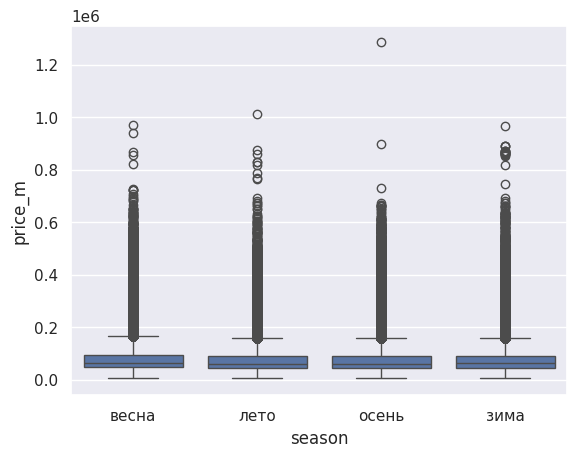

In [66]:
sns.boxplot(dfc, x='season', y='price_m')

<Axes: xlabel='season', ylabel='price_per_m'>

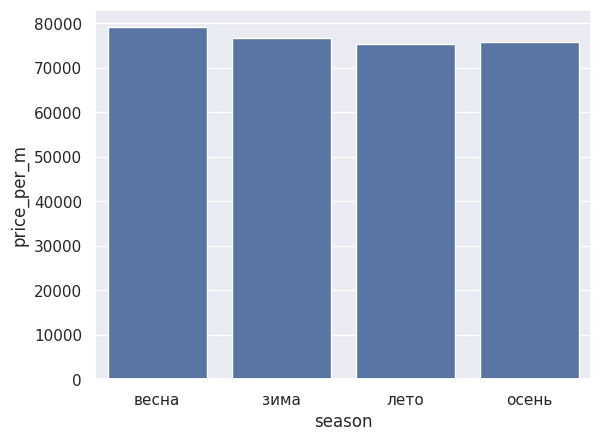

In [67]:
sns.barplot(price_ses, x='season', y='price_per_m')

В абсолютных значениях весной самая высокая цена за кв. м. (77561), а летом самая низкая (74121), однако, как мне кажется это разница не является какой-то значительной, проведем t-test и убедимся, являются ли различия в стоимости квадратного метра между самым "дорогим" и "дешевым" созном статистически значимыми.

H₀: Средняя стоимость квадратного метра летом равна средней стоимости квадратного метра весной.

H₁: Средняя стоимость квадратного метра летом не равна средней стоимости квадратного метра весной.
❗

In [68]:
#т-тест
from scipy import stats as st
results = st.ttest_ind(dfc.query('season=="лето"')['price_m'], dfc.query('season=="весна"')['price_m'], equal_var=False)
results
if results.pvalue < 0.05:
    print('Следует отвергнуть нулевую гипотезу')
else:
    print('Не удалось отвергнуть нулевую гипотезу.')
print('p-value', results.pvalue)

Следует отвергнуть нулевую гипотезу
p-value 0.0


Выводы:
В итоге t-test показал, что различие между средней стоимостью кв. метра летом и весной статистически значимые, а значит выгоднее всего покупать квартиру летом, а продавать вксной.

In [69]:
#посмотрим по месяцам
price_month = dfc.pivot_table(index='month', aggfunc={'price':'sum', 'area':'sum'}).reset_index().set_axis(['month','area','price'], axis='columns')
price_month['price_per_m'] = (price_month['price'] / price_month['area']).round(2)
price_month = price_month.sort_values(by='price_per_m', ascending=False)
price_month

,month,area,price,price_per_m
3,4,22651921.17,1849637232761,81654.76
2,3,24048781.75,1928465085416,80189.72
11,12,21644657.04,1684874561399,77842.52
6,7,16926864.45,1313235749633,77582.93
1,2,20186729.01,1548443664926,76706.02
10,11,21594776.04,1653174268171,76554.36
9,10,22147920.87,1685103767300,76084.06
8,9,22634327.07,1696194241543,74939.02
5,6,15321076.21,1145862343383,74789.94
0,1,14844040.70,1110143112030,74787.12


<Axes: xlabel='month', ylabel='price_m'>

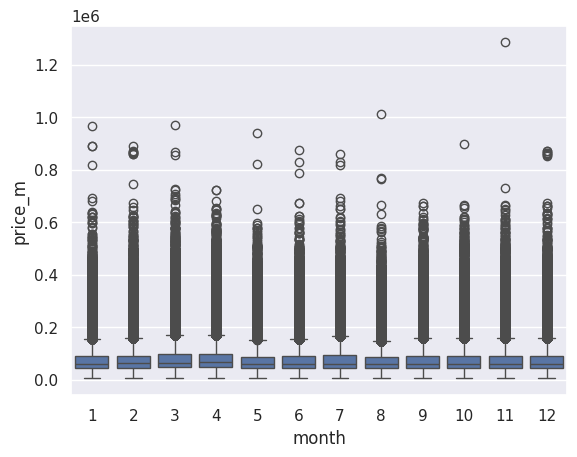

In [70]:
sns.boxplot(dfc, x='month', y='price_m')

<Axes: xlabel='month', ylabel='price_per_m'>

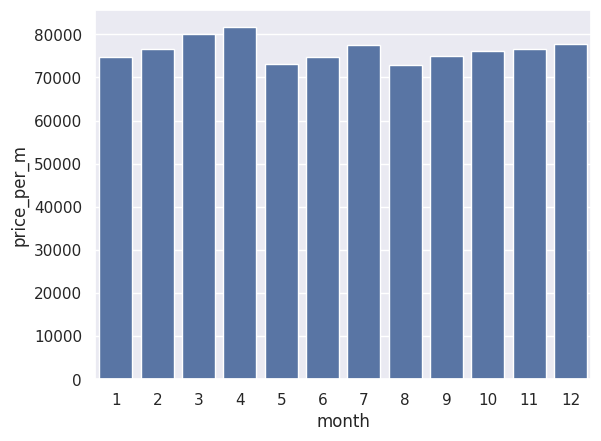

In [71]:
sns.barplot(price_month, x='month', y='price_per_m')

Вывод:

##Определите от каких признаков зависит стоимость объекта недвижимости. Найдите скрытые закономерности.

In [72]:
dfc[['region','building_type','level','levels','rooms','area', 'kitchen_area','price_m','month']].corr()

,region,building_type,level,levels,rooms,area,kitchen_area,price_m,month
region,1.000000,-0.137328,-0.127527,-0.179769,-0.072462,-0.009475,-0.118977,-0.462916,-0.031026
building_type,-0.137328,1.000000,-0.112346,-0.177533,0.022044,-0.020606,0.001162,-0.001004,0.012009
level,-0.127527,-0.112346,1.000000,0.658726,-0.096288,0.040654,0.205017,0.241971,0.001215
levels,-0.179769,-0.177533,0.658726,1.000000,-0.153688,0.061036,0.309662,0.359118,0.001712
rooms,-0.072462,0.022044,-0.096288,-0.153688,1.000000,0.733610,0.155722,-0.086995,0.015243
area,-0.009475,-0.020606,0.040654,0.061036,0.733610,1.000000,0.422311,-0.050414,0.001210
kitchen_area,-0.118977,0.001162,0.205017,0.309662,0.155722,0.422311,1.000000,0.140511,0.008846
price_m,-0.462916,-0.001004,0.241971,0.359118,-0.086995,-0.050414,0.140511,1.000000,-0.014539
month,-0.031026,0.012009,0.001215,0.001712,0.015243,0.001210,0.008846,-0.014539,1.000000


<Axes: xlabel='rooms', ylabel='price'>

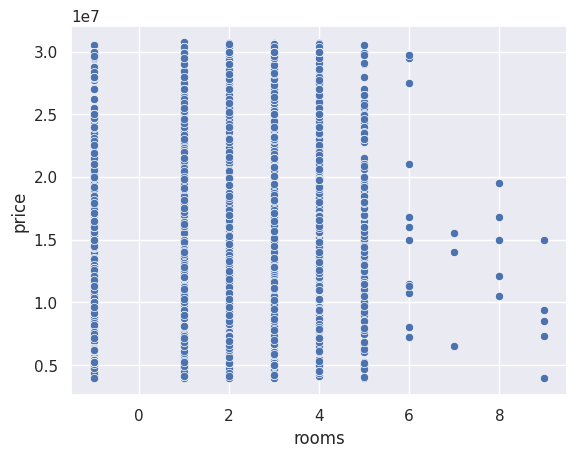

In [73]:
sns.scatterplot(dfc[dfc['reg_name']=='Москва'], x='rooms', y='price')

In [74]:
dfc.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4443725 entries, 3 to 4443727
Data columns (total 16 columns):
 #   Column         Dtype         
---  ------         -----         
 0   price          int64         
 1   date           datetime64[ns]
 2   region         int64         
 3   building_type  int64         
 4   level          int64         
 5   levels         int64         
 6   rooms          int64         
 7   area           float64       
 8   kitchen_area   float64       
 9   object_type    boolean       
 10  reg_name       object        
 11  price_m        float64       
 12  ym             object        
 13  year           object        
 14  month          int32         
 15  season         object        
dtypes: boolean(1), datetime64[ns](1), float64(3), int32(1), int64(6), object(4)
memory usage: 534.0+ MB


In [75]:

X, y = dfc[(dfc['kitchen_area'].notna())&(dfc['year']=='2020')].drop(['price','reg_name','price_m','date','ym','season','year'], axis=1), dfc[(dfc['kitchen_area'].notna())&(dfc['year']=='2020')]['price_m']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=1)

model = xgb.XGBRegressor()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print(f'R^2 score: {r2_score(y_test, predictions):.3f}')

R^2 score: 0.832


In [76]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import numpy as np

In [77]:
r2 = r2_score(y_test, predictions)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
mape = mean_absolute_percentage_error(y_test, predictions) * 100  # в процентах
std_error = np.std(y_test - predictions)
print(f"R² (коэффициент детерминации): {r2:.4f}")
print(f"MAE (средняя абсолютная ошибка): {mae:,.0f}")
print(f"RMSE (корень из MSE): {rmse:,.0f}")
print(f"MAPE (средняя абсолютная % ошибка): {mape:.2f}%")
print(f"Std Error (стандартное отклонение ошибок): {std_error:,.0f}")

R² (коэффициент детерминации): 0.8317
MAE (средняя абсолютная ошибка): 14,187
RMSE (корень из MSE): 21,994
MAPE (средняя абсолютная % ошибка): 18.78%
Std Error (стандартное отклонение ошибок): 21,994


In [78]:
xgb_fi = pd.Series(model.feature_importances_, index=model.feature_names_in_).sort_values(ascending=False)
print(xgb_fi)

region           0.703934
month            0.058699
levels           0.050539
rooms            0.047537
building_type    0.047282
object_type      0.038357
area             0.026562
kitchen_area     0.015947
level            0.011142
dtype: float32


In [79]:

X1, y1 = dfc[(dfc['kitchen_area'].notna())&(dfc['year']=='2020')&(dfc['reg_name']=='Москва')].drop(['price','reg_name','price_m','date','ym','season','year','region'], axis=1), dfc[(dfc['kitchen_area'].notna())&(dfc['year']=='2020')&(dfc['reg_name']=='Москва')]['price']
X_train, X_test, y_train, y_test = train_test_split(X1, y1, test_size=0.2, shuffle=True, random_state=1)

model2 = xgb.XGBRegressor()
model2.fit(X_train, y_train)
predictions2 = model2.predict(X_test)
print(f'R^2 score: {r2_score(y_test, predictions2):.3f}')

R^2 score: 0.726


In [80]:
xgb_fi = pd.Series(model2.feature_importances_, index=model2.feature_names_in_).sort_values(ascending=False)
print(xgb_fi)

area             0.432554
object_type      0.152348
building_type    0.145045
levels           0.082620
month            0.066975
rooms            0.060800
kitchen_area     0.036779
level            0.022880
dtype: float32


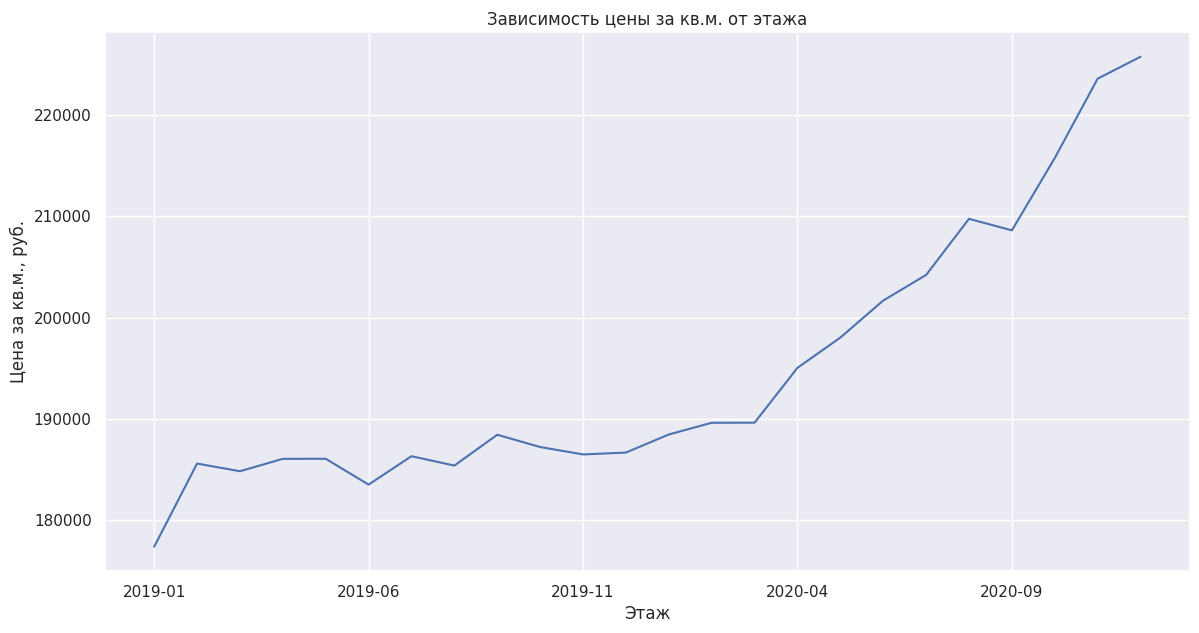

In [81]:
price =  dfc[((dfc['year']=='2020')|(dfc['year']=='2019'))&(dfc['reg_name']=='Москва')].groupby(['ym'])['price_m'].mean()
price.plot(
    figsize=(14,7),
    xlabel='Этаж',
    ylabel='Цена за кв.м., руб.',
    title='Зависимость цены за кв.м. от этажа')
plt.show()

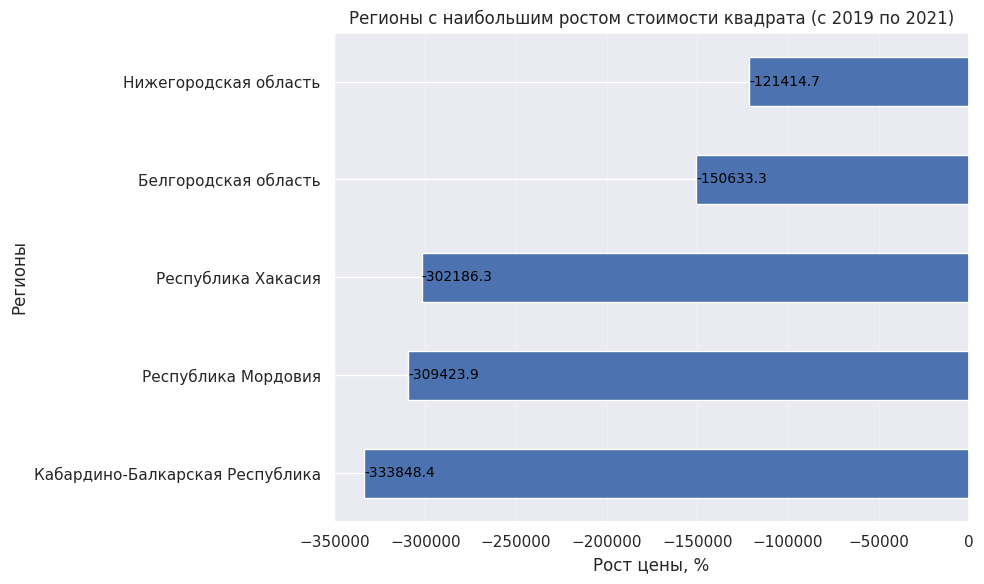

In [82]:
df_izm = dfc_filtered1.pivot_table(
    index='reg_name',
    columns='year',
    values='area',
    aggfunc='sum',
    fill_value=0
)
df_izm
df_izm['pct_change'] = (df_izm['2021'] - df_izm['2019'])

leaders = df_izm.sort_values('pct_change', ascending=False).head(5)
leaders = leaders.sort_values('pct_change', ascending=True)
ax = leaders['pct_change'].plot(kind='barh', figsize=(10, 6))

for i, (idx, value) in enumerate(leaders['pct_change'].items()):
    ax.text(value + 0.5, i, f'{value:.1f}',
            va='center', ha='left', fontsize=10, color='black')

plt.title('Регионы с наибольшим ростом стоимости квадрата (c 2019 по 2021)')
plt.xlabel('Рост цены, %')
plt.ylabel('Регионы')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## Выдвинете и проверьте собственную гипотезу статистическими методами

In [83]:
# H0: цена за кв метр на вторичном и первичнм рынке не отличаются
# H1: цена за кв метр на вторичном и первичнм рынке отличаются
results = st.ttest_ind(dfc.query('object_type==1')['price_m'], dfc.query('object_type==0')['price_m'], equal_var=False)
results
if results.pvalue < 0.05:
    print('Следует отвергнуть нулевую гипотезу')
else:
    print('Не удалось отвергнуть нулевую гипотезу.')
print('p-value', results.pvalue)

/tmp/ipykernel_3633/202221227.py:3: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  results = st.ttest_ind(dfc.query('object_type==1')['price_m'], dfc.query('object_type==0')['price_m'], equal_var=False)
/tmp/ipykernel_3633/202221227.py:3: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  results = st.ttest_ind(dfc.query('object_type==1')['price_m'], dfc.query('object_type==0')['price_m'], equal_var=False)


Следует отвергнуть нулевую гипотезу
p-value 0.0


# Анализ рынка жилой недвижимости России

## Цель исследования

Цель проекта — изучить объявления о продаже жилой недвижимости в России за 2018–2021 годы, выявить различия в стоимости квадратного метра по регионам, сезонам и характеристикам объектов, а также построить модель прогнозирования цены.

## Данные

Основной источник — набор `realty_18_21.csv` из [репозитория Realty](https://github.com/Inf1nity544/Realty). В исходной таблице содержится **5 477 006 объявлений** за период с **19 февраля 2018 года по 1 мая 2021 года**. Каждая запись соответствует объявлению; идентификатор объекта в наборе отсутствует.

Использованы следующие признаки:

- цена объявления и дата его размещения;
- код региона;
- тип здания;
- этаж и этажность дома;
- число комнат, включая отдельный код для студий;
- общая площадь и площадь кухни;
- тип рынка: первичный или вторичный.

Для расшифровки регионов использован файл `region.csv`: в таблице соответствий содержится 84 кода, и для всех регионов анализируемой выборки было найдено наименование. Основная исследуемая величина — **цена квадратного метра**, рассчитанная как отношение цены объекта к его общей площади.

## Подготовка данных

На этапе проверки и очистки данных:

1. Дата объявления преобразована в формат даты, тип рынка приведён к логическому признаку.
2. Удалены **365 записей с отрицательной ценой**, **343 записи с некорректным кодом числа комнат** и объявления, где указанный этаж превышал этажность здания.
3. Нулевая площадь кухни и значения площади кухни, превышавшие общую площадь объекта, признаны некорректными и заменены пропусками.
4. Удалены полные дубликаты.
5. Для исключения нетипичных предложений применён фильтр цены по регионам: отсечены значения ниже 5-го и выше 95-го процентилей. Из **5 240 018** записей на этом этапе исключено **516 344 (9,85%)**, осталось **4 723 674**.
6. По площади оставлены объекты от **13,7 до 106 м²**: верхняя граница соответствует 99-му процентилю.
7. Из анализа исключён февраль 2018 года как неполный период наблюдений.

После указанных преобразований, объединения с таблицей регионов и отбора записей с заполненной площадью кухни итоговая аналитическая выборка составила **4 443 725 объявлений**. В ней оставались пропуски площади кухни: до отбора полных наблюдений в очищенных данных их было **226 407**.

Для оценки возможности восстановления площади кухни была обучена модель XGBoost; полученное значение **R² = 0,506**. Однако в последующих расчётах пропуски фактически не заполнялись: использовались записи с известной площадью кухни. Поэтому результаты анализа и моделирования относятся к подвыборке без пропусков по этому признаку.

## Исследовательский анализ

### Структура рынка

В сравнении по суммарной площади объявлений вторичный рынок составил приблизительно **70,7%**, первичный — **29,3%**. Доли рынков анализировались также в динамике по месяцам и регионам. В начале временного ряда наблюдались заметные колебания, а распределение предложений между первичным и вторичным рынками различалось по регионам.

Исследование цен включало сравнение регионов, типов зданий, типов рынка и этажей. В сохранённых графиках отмечена выраженная региональная дифференциация стоимости квадратного метра. Также автором ноутбука отмечено, что кирпично-монолитные дома в рассмотренной выборке в среднем дороже других типов зданий. Численные значения для этих отдельных сравнений в таблицах ноутбука не сохранены, поэтому выводы по ним носят описательный характер.

### Сезонные и месячные различия

В сезонной сводной таблице отношение суммарной цены к суммарной площади составило:

| Сезон | Цена за м², руб. |
|---|---:|
| Весна | 79 153,32 |
| Зима | 76 637,47 |
| Осень | 75 846,61 |
| Лето | 75 363,17 |

Таким образом, в этой сводке наибольшее значение приходится на весну, наименьшее — на лето. Разница между ними составляет около **3 790 руб./м²**. Отдельно по месяцам наибольшее значение было в марте — **81 654,76 руб./м²**, наименьшее — в августе — **72 818,78 руб./м²**.

Для проверки сезонного различия был проведён двухвыборочный t-тест Уэлча для наблюдений по цене квадратного метра весной и летом. В ноутбуке p-value отображён как `0.0` из-за округления; корректная интерпретация — **p < 0,001**. На уровне значимости 5% нулевая гипотеза о равенстве средних отвергается. Результат указывает на статистически значимое различие в данной выборке, но сам по себе не доказывает, что сезон является причиной изменения цены, и не гарантирует аналогичного эффекта на других периодах.

### Проверка гипотезы о типе рынка

Проверена гипотеза о различии цены квадратного метра на первичном и вторичном рынках с помощью t-теста Уэлча. Нулевая гипотеза об отсутствии различий отвергнута; p-value в сохранённом выводе также округлён до `0.0` (то есть **p < 0,001**). Тест подтверждает наличие статистического различия, но не определяет его практическую величину. Кроме того, в одной из визуализаций сравнения рынков подписи первичного и вторичного сегментов, судя по кодировке признака, переставлены местами; поэтому для выводов о направлении различия следует опираться на проверенные расчёты, а не на эту диаграмму.

## Моделирование

Для прогнозирования цены квадратного метра построена модель **XGBoost Regressor**. Использованы объявления за 2020 год; данные разделены случайным образом на обучающую и тестовую выборки в пропорции **80/20**. В качестве признаков включены регион, месяц, этажность, число комнат, тип здания и рынка, общая площадь, площадь кухни и этаж.

Результаты на тестовой выборке:

| Метрика | Значение |
|---|---:|
| R² | 0,8317 |
| MAE | 14 187 руб./м² |
| RMSE | 21 994 руб./м² |
| MAPE | 18,78% |

Наибольшая важность признака по оценке модели пришлась на код региона — **0,704**. Далее следовали месяц (**0,059**), этажность (**0,051**), число комнат (**0,048**) и тип здания (**0,047**). Эти значения описывают вклад признаков в конкретную модель и не являются доказательством причинно-следственной зависимости.

Дополнительно построена отдельная модель для Москвы. В отличие от общероссийской модели, она прогнозировала **полную цену объекта**, а не цену квадратного метра. Для неё получено **R² = 0,726**; наиболее важными признаками стали общая площадь (**0,433**), тип рынка (**0,152**) и тип здания (**0,145**). Показатели двух моделей напрямую не сопоставимы из-за различия целевых переменных и географического охвата.

## Итоги и ограничения

Анализ показал, что в рассмотренной выборке стоимость квадратного метра различалась в зависимости от региона и времени размещения объявления; также статистически значимыми оказались различия между сезонными группами и типами рынка. Модель XGBoost для общероссийской выборки за 2020 год показала R² около **0,83**, однако средняя абсолютная процентная ошибка составила **18,78%**.

Результаты следует интерпретировать с учётом ограничений:

- набор содержит объявления, а не подтверждённые цены сделок;
- наблюдаемый период ограничен февралем 2018 — маем 2021 года;
- отбор по региональным процентилям цены и по площади изменил состав анализируемой выборки;
- пропуски площади кухни не были восстановлены, а исключались из дальнейшего анализа;
- случайное разбиение данных не проверяет качество прогноза на более позднем временном периоде;
- код региона использован как числовой признак, хотя это идентификатор, а не количественная характеристика;
- статистическая значимость при большом объёме данных не равнозначна большой практической значимости.

Таким образом, проект демонстрирует подход к очистке и исследованию данных объявлений о недвижимости, сравнительному анализу рынка и построению модели прогноза. Полученные закономерности характеризуют историческую выборку и не должны рассматриваться как самостоятельная оценка текущей рыночной стоимости или инвестиционная рекомендация.